## Load and prepare the data

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load both downloaded files
repairs = pd.read_csv("cleaned_repairs_en.csv")
categories = pd.read_csv("cleaned_categories (1).csv")


# Convert event_date to datetime
repairs["event_date"] = pd.to_datetime(
    repairs["event_date"], errors="coerce"
)

# Add appliance category names to repair records
df = repairs.merge(
    categories,
    on="product_category_id",
    how="left"
)

print("Dataset shape:", df.shape)
print("\nDate range:")
print(df["event_date"].min(), "to", df["event_date"].max())

print("\nAvailable columns:")
print(df.columns.tolist())

df.head()


Dataset shape: (113049, 13)

Date range:
2012-06-20 00:00:00 to 2025-07-30 00:00:00

Available columns:
['id', 'data_provider', 'country', 'product_category_id', 'brand', 'year_of_manufacture', 'product_age', 'repair_status', 'repair_barrier', 'event_date', 'problem', 'problem_en', 'product_category']


,id,data_provider,country,product_category_id,brand,year_of_manufacture,product_age,repair_status,repair_barrier,event_date,problem,problem_en,product_category
0,anstiftung_26663,anstiftung,DEU,11,MARLEY,NaN,NaN,End of life,NaN,2025-07-28,wackelkontakt am kopfhörer.,wobble contact on the headphone.,Headphones
1,anstiftung_26666,anstiftung,DEU,16,DELL,NaN,NaN,End of life,NaN,2025-07-28,kaputt. hardware.,broken. hardware.,Laptop
2,anstiftung_26770,anstiftung,DEU,40,HILO,NaN,NaN,Repairable,NaN,2025-07-28,Bügeleisen wird nicht mehr heiß. Schalter defekt.,Iron no longer gets hot. Switch broken.,Iron
3,anstiftung_26627,anstiftung,DEU,37,THERMOMIX,NaN,NaN,Fixed,NaN,2025-07-28,Herstellung der endgültigen Kipphilfe aus Alth...,Production of the final tipping aid from old w...,Food processor
4,anstiftung_26664,anstiftung,DEU,16,ACER,NaN,NaN,Fixed,NaN,2025-07-28,kubuntu installiert.,kubuntu installed.,Laptop


## Data Qualtity Checks

In [ ]:

# 4. DATA QUALITY CHECKS

# 1. Basic dataset information
print("========== DATASET OVERVIEW ==========")
print("Total repair records:", len(df))
print("Total columns:", len(df.columns))

# 2. Missing values
print("\n========== MISSING VALUES ==========")
missing_values = df.isnull().sum()
missing_values = missing_values[missing_values > 0]

if len(missing_values) > 0:
    print(missing_values.sort_values(ascending=False))
else:
    print("No missing values found.")

# 3. Missing event dates
print("\n========== DATE CHECK ==========")
print("Records with missing event dates:",
      df["event_date"].isna().sum())

valid_dates = df["event_date"].dropna()

if len(valid_dates) > 0:
    print("First recorded date:", valid_dates.min())
    print("Last recorded date:", valid_dates.max())

# 4. Missing appliance categories
print("\n========== CATEGORY CHECK ==========")
print("Records with missing appliance categories:",
      df["product_category"].isna().sum())

print("\nTop 10 categories with most records:")
print(df["product_category"].value_counts().head(10))

# 5. Monthly zero-record check
print("\n========== MONTHLY RECORD CHECK ==========")

monthly_check = (
    df.dropna(subset=["event_date"])
      .set_index("event_date")
      .resample("MS")
      .size()
      .asfreq("MS", fill_value=0)
)

print("Total calendar months:", len(monthly_check))
print("Months with zero records:",
      (monthly_check == 0).sum())

print("\nZero-record months:")
print(monthly_check[monthly_check == 0])

# 6. Duplicate-row check
print("\n========== DUPLICATE CHECK ==========")
print("Exact duplicate rows:", df.duplicated().sum())

# 7. Final summary
print("\n========== DATA QUALITY SUMMARY ==========")
print("Total records:", len(df))
print("Records with valid dates:", df["event_date"].notna().sum())
print("Unique appliance categories:",
      df["product_category"].nunique())


========== DATASET OVERVIEW ==========
Total repair records: 113049
Total columns: 13

========== MISSING VALUES ==========
repair_barrier         101978
product_age             72477
year_of_manufacture     71151
dtype: int64

========== DATE CHECK ==========
Records with missing event dates: 0
First recorded date: 2012-06-20 00:00:00
Last recorded date: 2025-07-30 00:00:00

========== CATEGORY CHECK ==========
Records with missing appliance categories: 0

Top 10 categories with most records:
product_category
Vacuum                   10378
Coffee maker              8597
Power tool                8382
Hi-Fi separates           8018
Lamp                      7103
Small kitchen item        5969
Food processor            5370
Small home electrical     5330
Watch/clock               4784
Portable radio            4708
Name: count, dtype: int64

========== MONTHLY RECORD CHECK ==========
Total calendar months: 158
Months with zero records: 23

Zero-record months:
event_date
2012-07-01    0


###Missing-value visualisation

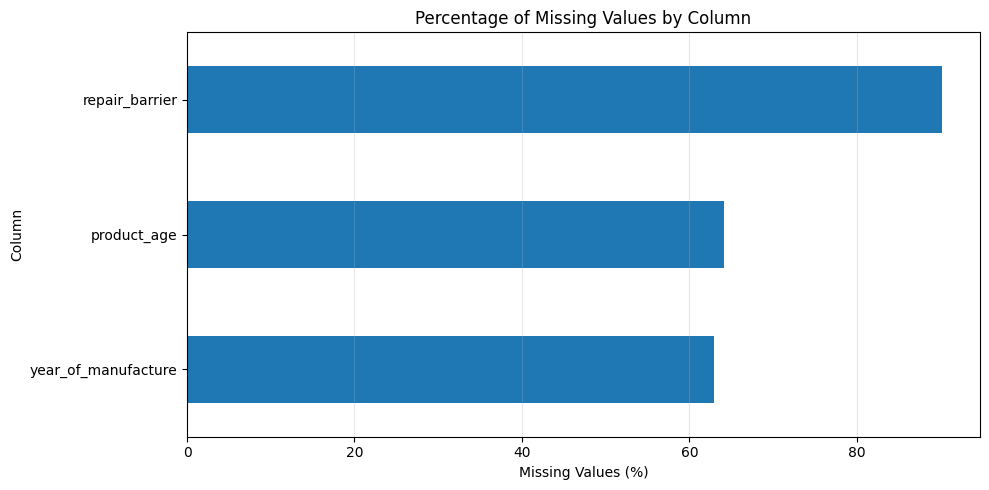

Missing-value summary:
                     Missing Count  Missing Percentage
year_of_manufacture          71151               62.94
product_age                  72477               64.11
repair_barrier              101978               90.21

Conclusion:
All records have valid event dates and appliance categories.
No exact duplicate rows or zero-record months were found.
Some columns have substantial missing data.


In [ ]:

# Missing values by column

missing_count = df.isnull().sum()
missing_count = missing_count[missing_count > 0].sort_values()

missing_percent = (missing_count / len(df)) * 100

plt.figure(figsize=(10, 5))
missing_percent.plot(kind="barh")

plt.title("Percentage of Missing Values by Column")
plt.xlabel("Missing Values (%)")
plt.ylabel("Column")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

print("Missing-value summary:")
print(pd.DataFrame({
    "Missing Count": missing_count,
    "Missing Percentage": missing_percent.round(2)
}))
print("\nConclusion:")
print("All records have valid event dates and appliance categories.")
print("No exact duplicate rows or zero-record months were found.")
print("Some columns have substantial missing data.")


## Analyze which appliances have the most repair records

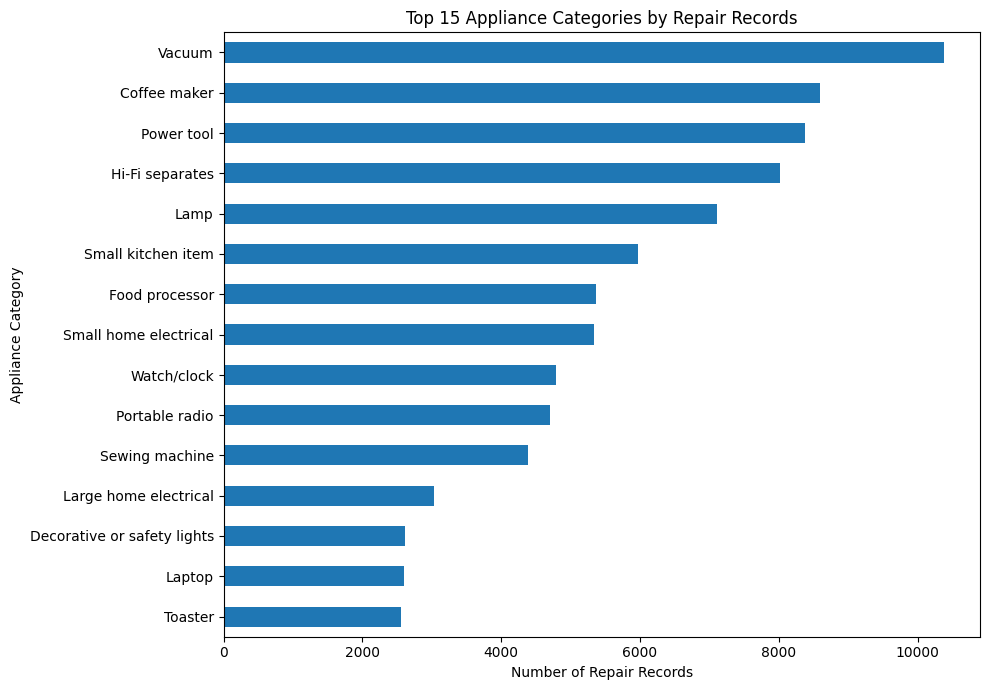

Top appliance categories:
product_category
Vacuum                         10378
Coffee maker                    8597
Power tool                      8382
Hi-Fi separates                 8018
Lamp                            7103
Small kitchen item              5969
Food processor                  5370
Small home electrical           5330
Watch/clock                     4784
Portable radio                  4708
Sewing machine                  4389
Large home electrical           3034
Decorative or safety lights     2608
Laptop                          2602
Toaster                         2556
Name: count, dtype: int64


In [ ]:

category_counts = (
    df["product_category"]
    .value_counts()
    .head(15)
    .sort_values()
)

plt.figure(figsize=(10, 7))
category_counts.plot(kind="barh")

plt.title("Top 15 Appliance Categories by Repair Records")
plt.xlabel("Number of Repair Records")
plt.ylabel("Appliance Category")
plt.tight_layout()
plt.show()

print("Top appliance categories:")
print(df["product_category"].value_counts().head(15))



##Analyze how repair records change over time

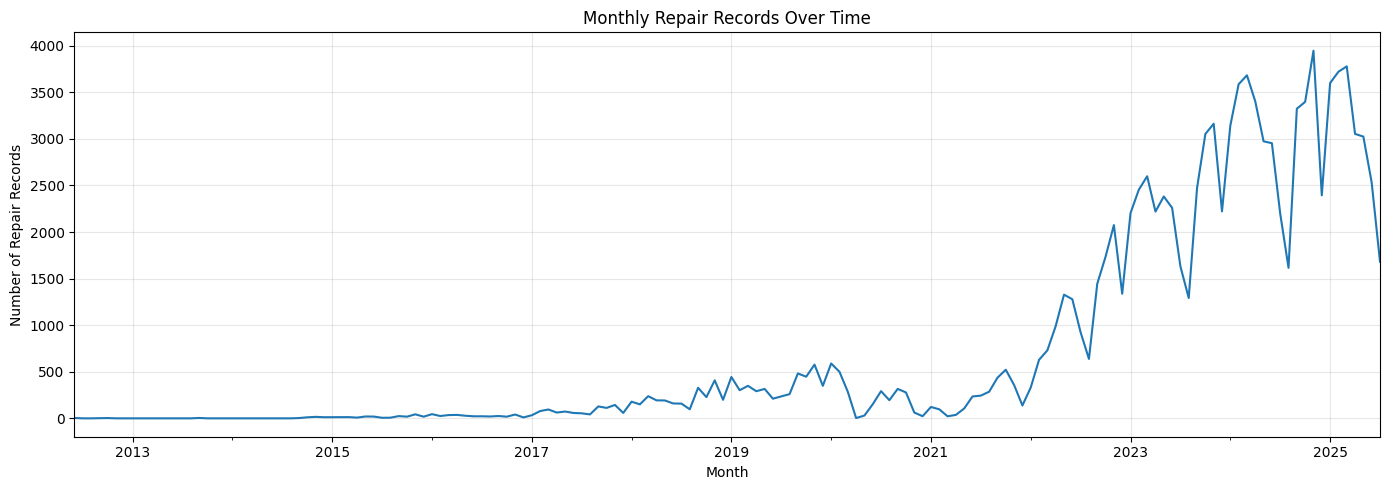

event_date
2024-08-01    1616
2024-09-01    3324
2024-10-01    3398
2024-11-01    3947
2024-12-01    2394
2025-01-01    3600
2025-02-01    3721
2025-03-01    3779
2025-04-01    3054
2025-05-01    3025
2025-06-01    2531
2025-07-01    1682
Freq: MS, dtype: int64


In [ ]:

monthly_demand = (
    df.dropna(subset=["event_date"])
      .set_index("event_date")
      .resample("MS")
      .size()
)

plt.figure(figsize=(14, 5))
monthly_demand.plot()

plt.title("Monthly Repair Records Over Time")
plt.xlabel("Month")
plt.ylabel("Number of Repair Records")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(monthly_demand.tail(12))


## Find the most frequently reported problems


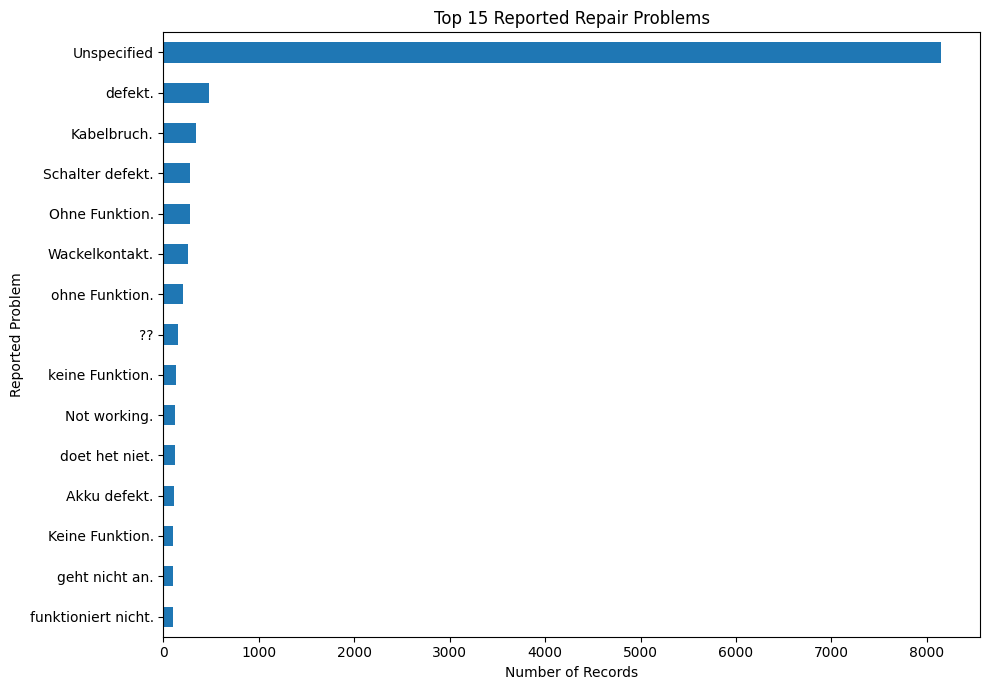

problem
Unspecified            8149
defekt.                 480
Kabelbruch.             337
Schalter defekt.        277
Ohne Funktion.          276
Wackelkontakt.          253
ohne Funktion.          203
??                      150
keine Funktion.         134
Not working.            123
doet het niet.          118
Akku defekt.            111
geht nicht an.          103
Keine Funktion.         103
funktioniert nicht.      98
Name: count, dtype: int64


In [ ]:

top_problems = (
    df["problem"]
    .fillna("Unspecified")
    .value_counts()
    .head(15)
    .sort_values()
)

plt.figure(figsize=(10, 7))
top_problems.plot(kind="barh")

plt.title("Top 15 Reported Repair Problems")
plt.xlabel("Number of Records")
plt.ylabel("Reported Problem")
plt.tight_layout()
plt.show()

print(df["problem"].value_counts().head(15))


##Analyze appliance categories vs. repair problems

In [ ]:

# Count records for each category-problem combination
category_problem = (
    df.groupby(
        ["product_category", "problem"],
        dropna=False
    )
    .size()
    .reset_index(name="record_count")
)

# Select the 10 categories with the most records
top_categories = (
    df["product_category"]
    .value_counts()
    .head(10)
    .index
)

# Show the top 3 recorded problems in each category
for category in top_categories:
    subset = category_problem[
        category_problem["product_category"] == category
    ]

    print(f"\n--- {category} ---")
    print(
        subset.sort_values("record_count", ascending=False)
        [["problem", "record_count"]]
        .head(3)
        .to_string(index=False)
    )



--- Vacuum ---
       problem  record_count
   Unspecified           790
  Akku defekt.            35
Ohne Funktion.            23

--- Coffee maker ---
    problem  record_count
Unspecified           569
      lekt.            18
   undicht.            15

--- Power tool ---
         problem  record_count
     Unspecified           748
Schalter defekt.            31
     Kabelbruch.            27

--- Hi-Fi separates ---
       problem  record_count
   Unspecified           594
       defekt.            41
Ohne Funktion.            24

--- Lamp ---
         problem  record_count
     Unspecified           421
Schalter defekt.            94
  Wackelkontakt.            52

--- Small kitchen item ---
       problem  record_count
   Unspecified           469
Ohne Funktion.            22
       defekt.            16

--- Food processor ---
    problem  record_count
Unspecified           308
Kabelbruch.            42
    defekt.            32

--- Small home electrical ---
    problem  rec

##Build a repair-demand forecasting baseline

            Actual  Previous Month  3-Month Average
event_date                                         
2025-02-01    3721            3600      3313.666667
2025-03-01    3779            3721      3238.333333
2025-04-01    3054            3779      3700.000000
2025-05-01    3025            3054      3518.000000
2025-06-01    2531            3025      3286.000000
2025-07-01    1682            2531      2870.000000

Previous Month
MAE: 379.33
RMSE: 501.55

3-Month Average
MAE: 671.67
RMSE: 718.79


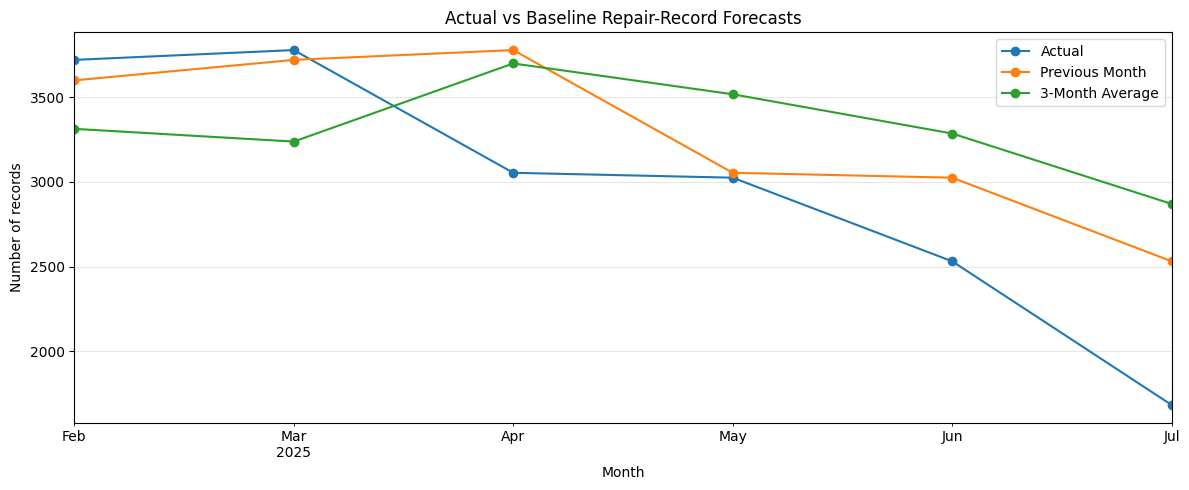

In [ ]:

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

monthly = (
    df.dropna(subset=["event_date"])
      .set_index("event_date")
      .resample("MS")
      .size()
      .asfreq("MS", fill_value=0)
)

# Use the final 6 months as a test period
train = monthly.iloc[:-6]
test = monthly.iloc[-6:]

if len(train) < 3:
    print("Not enough historical months for this comparison.")
else:
    previous_month_preds = []
    moving_average_preds = []
    history = list(train.values)

    for actual in test.values:
        previous_month_preds.append(history[-1])
        moving_average_preds.append(np.mean(history[-3:]))
        history.append(actual)

    results = pd.DataFrame({
        "Actual": test.values,
        "Previous Month": previous_month_preds,
        "3-Month Average": moving_average_preds
    }, index=test.index)

    print(results)

    for name in ["Previous Month", "3-Month Average"]:
        mae = mean_absolute_error(results["Actual"], results[name])
        rmse = np.sqrt(
            mean_squared_error(results["Actual"], results[name])
        )
        print(f"\n{name}")
        print("MAE:", round(mae, 2))
        print("RMSE:", round(rmse, 2))

    results.plot(figsize=(12, 5), marker="o")
    plt.title("Actual vs Baseline Repair-Record Forecasts")
    plt.xlabel("Month")
    plt.ylabel("Number of records")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()


##Test whether a seasonal pattern exists

In [ ]:

# Compare monthly counts with the same month one year earlier
seasonal_comparison = pd.DataFrame({
    "Current Year Records": monthly,
    "Previous Year Records": monthly.shift(12)
}).dropna()

print(seasonal_comparison.tail(12))

if len(seasonal_comparison) >= 12:
    seasonal_mae = mean_absolute_error(
        seasonal_comparison["Current Year Records"],
        seasonal_comparison["Previous Year Records"]
    )
    print("\nSeasonal naive MAE:", round(seasonal_mae, 2))
else:
    print(
        "\nNot enough year-over-year monthly comparisons "
        "for a reliable seasonal evaluation."
    )


            Current Year Records  Previous Year Records
event_date                                             
2024-08-01                  1616                 1292.0
2024-09-01                  3324                 2473.0
2024-10-01                  3398                 3053.0
2024-11-01                  3947                 3163.0
2024-12-01                  2394                 2222.0
2025-01-01                  3600                 3142.0
2025-02-01                  3721                 3587.0
2025-03-01                  3779                 3683.0
2025-04-01                  3054                 3403.0
2025-05-01                  3025                 2974.0
2025-06-01                  2531                 2954.0
2025-07-01                  1682                 2198.0

Seasonal naive MAE: 307.79


##Repair Demand Forecasting and Evaluation

Training period: 2012-06 to 2025-01
Testing period: 2025-02 to 2025-07

ACTUAL VS PREDICTED MONTHLY REPAIR RECORDS
            Actual  Previous Month  3-Month Average  Seasonal Naive  \
event_date                                                            
2025-02-01    3721            3600          3313.67            3587   
2025-03-01    3779            3600          3102.56            3683   
2025-04-01    3054            3600          3338.74            3403   
2025-05-01    3025            3600          3251.65            2974   
2025-06-01    2531            3600          3230.98            2954   
2025-07-01    1682            3600          3273.79            2198   

            Holt-Winters  
event_date                
2025-02-01       3760.30  
2025-03-01       3701.79  
2025-04-01       3310.47  
2025-05-01       3035.40  
2025-06-01       3095.16  
2025-07-01       2496.13  

MODEL PERFORMANCE COMPARISON
Forecasting Method    MAE   RMSE
    Seasonal Naive 261.50 315.37
    

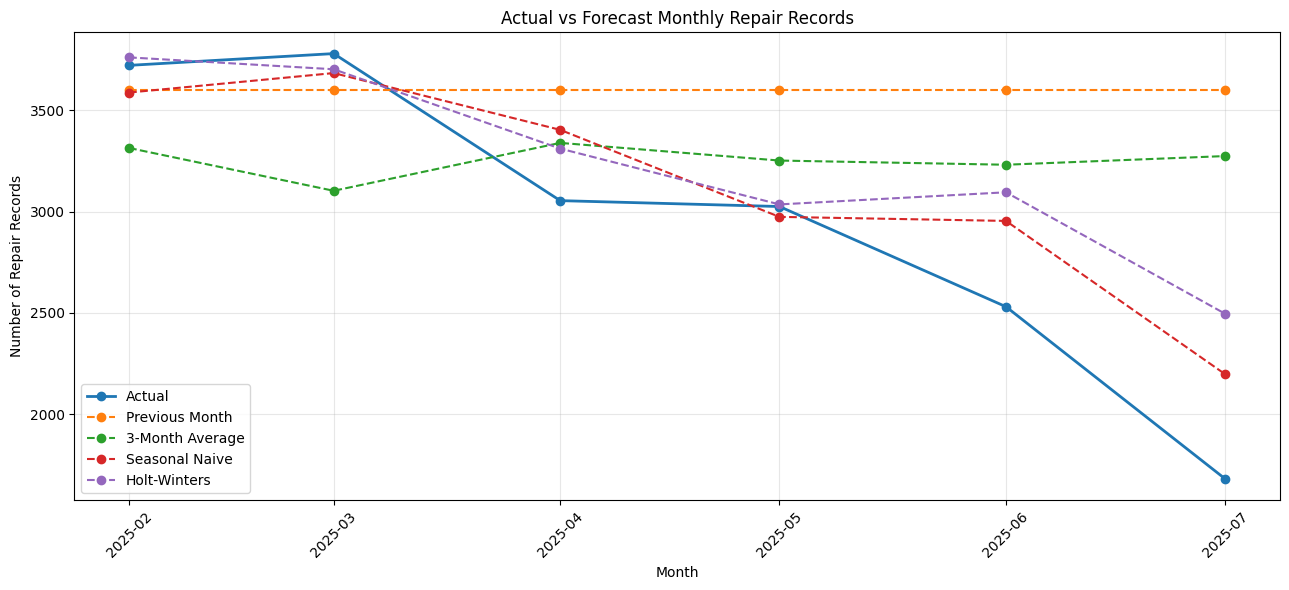

In [ ]:

# SECTION 9: Repair Demand Forecasting and Evaluation

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.metrics import mean_absolute_error, mean_squared_error

# 1. Prepare monthly repair records
monthly = (
    df.dropna(subset=["event_date"])
      .set_index("event_date")
      .resample("MS")
      .size()
      .asfreq("MS", fill_value=0)
)

# 2. Split data into training and testing periods
test_size = 6
train = monthly.iloc[:-test_size]
test = monthly.iloc[-test_size:]

print("Training period:", train.index.min().strftime("%Y-%m"),
      "to", train.index.max().strftime("%Y-%m"))
print("Testing period:", test.index.min().strftime("%Y-%m"),
      "to", test.index.max().strftime("%Y-%m"))

# 3. Previous Month model
# Repeat the last training month's value for all six months
previous_month_preds = np.repeat(train.iloc[-1], test_size)

# 4. Three-Month Average model
# Forecast recursively without using actual test values
history = list(train.values)
three_month_preds = []

for _ in range(test_size):
    prediction = np.mean(history[-3:])
    three_month_preds.append(prediction)
    history.append(prediction)

# 5. Seasonal Naive model
# Use the corresponding month from the previous year
seasonal_naive_preds = [
    train.loc[date - pd.DateOffset(years=1)]
    for date in test.index
]

# 6. Holt-Winters model
hw_model = ExponentialSmoothing(
    train,
    trend="add",
    seasonal="add",
    seasonal_periods=12,
    initialization_method="estimated"
).fit()

hw_preds = hw_model.forecast(steps=test_size)

# 7. Combine actual values and predictions
results = pd.DataFrame({
    "Actual": test.values,
    "Previous Month": previous_month_preds,
    "3-Month Average": three_month_preds,
    "Seasonal Naive": seasonal_naive_preds,
    "Holt-Winters": hw_preds.values
}, index=test.index)

print("\nACTUAL VS PREDICTED MONTHLY REPAIR RECORDS")
print(results.round(2))

# 8. Evaluate all models using MAE and RMSE
evaluation = []

for model_name in [
    "Previous Month",
    "3-Month Average",
    "Seasonal Naive",
    "Holt-Winters"
]:
    mae = mean_absolute_error(
        results["Actual"], results[model_name]
    )

    rmse = np.sqrt(mean_squared_error(
        results["Actual"], results[model_name]
    ))

    evaluation.append({
        "Forecasting Method": model_name,
        "MAE": mae,
        "RMSE": rmse
    })

evaluation = pd.DataFrame(evaluation)
evaluation = evaluation.sort_values("MAE").reset_index(drop=True)

print("\nMODEL PERFORMANCE COMPARISON")
print(evaluation.round(2).to_string(index=False))

best_mae = evaluation.loc[evaluation["MAE"].idxmin()]
best_rmse = evaluation.loc[evaluation["RMSE"].idxmin()]

print("\nBest method by MAE:",
      best_mae["Forecasting Method"],
      "-", round(best_mae["MAE"], 2))

print("Best method by RMSE:",
      best_rmse["Forecasting Method"],
      "-", round(best_rmse["RMSE"], 2))

# 9. Plot actual values against all model predictions
plt.figure(figsize=(13, 6))

plt.plot(
    results.index, results["Actual"],
    marker="o", linewidth=2, label="Actual"
)

for model_name in [
    "Previous Month",
    "3-Month Average",
    "Seasonal Naive",
    "Holt-Winters"
]:
    plt.plot(
        results.index, results[model_name],
        marker="o", linestyle="--", label=model_name
    )

plt.title("Actual vs Forecast Monthly Repair Records")
plt.xlabel("Month")
plt.ylabel("Number of Repair Records")
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(results.index, results.index.strftime("%Y-%m"), rotation=45)
plt.tight_layout()
plt.show()


##Evaluate the forecast

FORECAST ERRORS (Actual - Predicted)
            Previous Month  3-Month Average  Seasonal Naive  Holt-Winters
event_date                                                               
2025-02-01             121           407.33             134        -39.30
2025-03-01             179           676.44              96         77.21
2025-04-01            -546          -284.74            -349       -256.47
2025-05-01            -575          -226.65              51        -10.40
2025-06-01           -1069          -699.98            -423       -564.16
2025-07-01           -1918         -1591.79            -516       -814.13

ABSOLUTE FORECAST ERRORS
            Previous Month  3-Month Average  Seasonal Naive  Holt-Winters
event_date                                                               
2025-02-01             121           407.33             134         39.30
2025-03-01             179           676.44              96         77.21
2025-04-01             546           284.74      

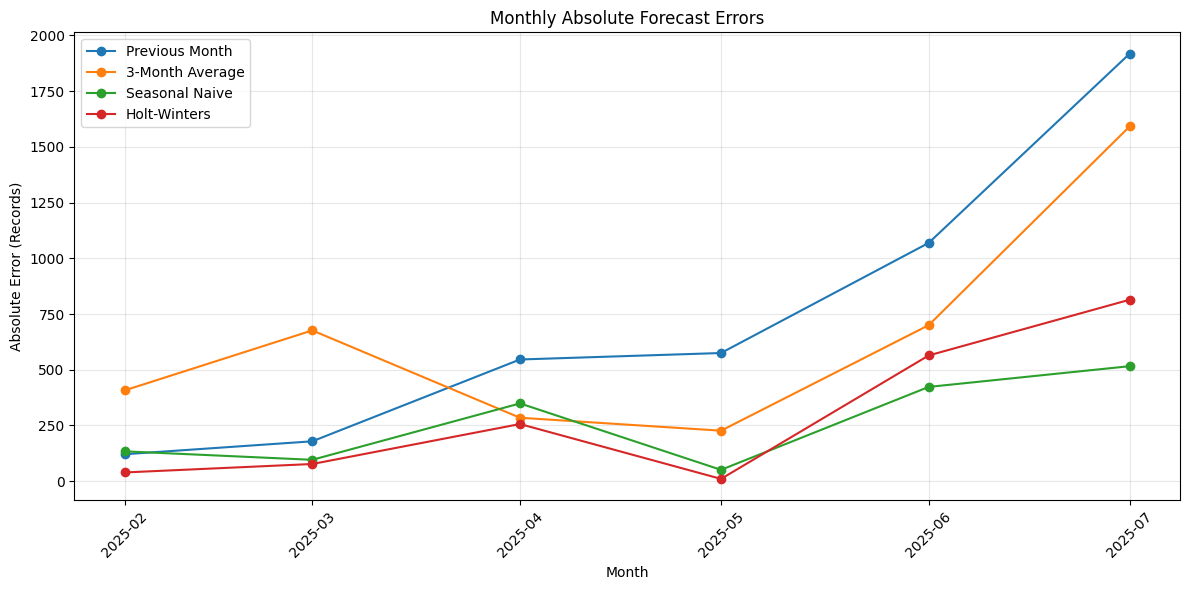


INTERPRETATION
Lowest MAE: Seasonal Naive (261.50)
Lowest RMSE: Seasonal Naive (315.37)

Note:
Positive error means the model underpredicted repair records.
Negative error means the model overpredicted repair records.
Lower MAE and RMSE generally indicate better forecasting accuracy.


In [ ]:

# SECTION 10: Forecast Error Analysis

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Calculate forecast errors
# Error = Actual - Predicted

model_names = [
    "Previous Month",
    "3-Month Average",
    "Seasonal Naive",
    "Holt-Winters"
]

errors = pd.DataFrame(index=results.index)

for model in model_names:
    errors[model] = results["Actual"] - results[model]

print("FORECAST ERRORS (Actual - Predicted)")
print(errors.round(2))

# 2. Calculate absolute errors
absolute_errors = errors.abs()

print("\nABSOLUTE FORECAST ERRORS")
print(absolute_errors.round(2))

# 3. Calculate evaluation metrics
metrics = []

for model in model_names:
    mae = absolute_errors[model].mean()
    rmse = np.sqrt((errors[model] ** 2).mean())

    metrics.append({
        "Forecasting Method": model,
        "MAE": mae,
        "RMSE": rmse
    })

error_summary = pd.DataFrame(metrics).sort_values("MAE")

print("\nFORECAST ERROR SUMMARY")
print(error_summary.round(2).to_string(index=False))

# 4. Plot absolute forecast errors for each month
plt.figure(figsize=(12, 6))

for model in model_names:
    plt.plot(
        absolute_errors.index,
        absolute_errors[model],
        marker="o",
        label=model
    )

plt.title("Monthly Absolute Forecast Errors")
plt.xlabel("Month")
plt.ylabel("Absolute Error (Records)")
plt.xticks(absolute_errors.index,
           absolute_errors.index.strftime("%Y-%m"),
           rotation=45)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 5. Explain the best-performing models
best_mae_model = error_summary.loc[
    error_summary["MAE"].idxmin()
]
best_rmse_model = error_summary.loc[
    error_summary["RMSE"].idxmin()
]

print("\nINTERPRETATION")
print(
    f"Lowest MAE: {best_mae_model['Forecasting Method']} "
    f"({best_mae_model['MAE']:.2f})"
)
print(
    f"Lowest RMSE: {best_rmse_model['Forecasting Method']} "
    f"({best_rmse_model['RMSE']:.2f})"
)

print("\nNote:")
print("Positive error means the model underpredicted repair records.")
print("Negative error means the model overpredicted repair records.")
print("Lower MAE and RMSE generally indicate better forecasting accuracy.")


##Forecast the Next Six Months

SIX-MONTH REPAIR RECORD FORECAST
                Previous Month  3-Month Average  Seasonal Naive  Holt-Winters
Forecast Month                                                               
2025-08-01                1682             2413            1616          1602
2025-09-01                1682             2209            3324          3273
2025-10-01                1682             2101            3398          3421
2025-11-01                1682             2241            3947          3843
2025-12-01                1682             2183            2394          2363
2026-01-01                1682             2175            3600          3496

HOLT-WINTERS FORECAST SUMMARY
Total predicted records: 17999
Average predicted records per month: 2999.76


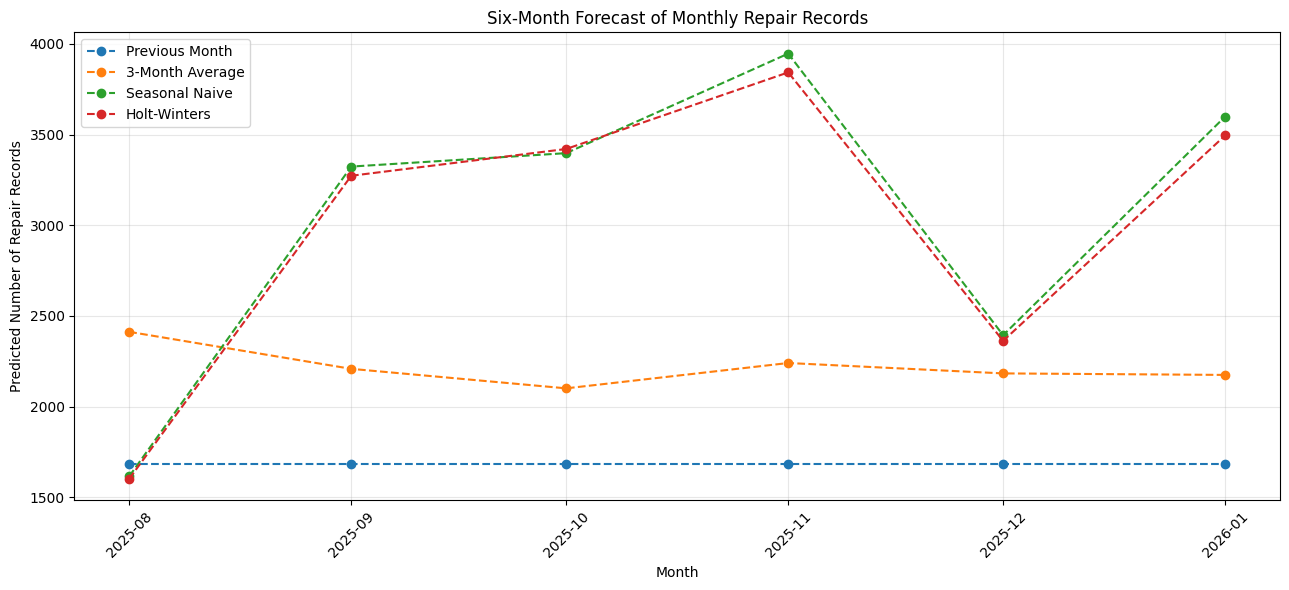

In [ ]:

# SECTION 11: Forecast the Next Six Months

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.holtwinters import ExponentialSmoothing

# 1. Prepare the complete monthly series
monthly = (
    df.dropna(subset=["event_date"])
      .set_index("event_date")
      .resample("MS")
      .size()
      .asfreq("MS", fill_value=0)
)

# 2. Set the forecast period
forecast_steps = 6

# 3. Previous Month forecast
previous_month_forecast = np.repeat(
    monthly.iloc[-1], forecast_steps
)

# 4. Three-Month Average forecast
history = list(monthly.values)
three_month_forecast = []

for _ in range(forecast_steps):
    prediction = np.mean(history[-3:])
    three_month_forecast.append(prediction)
    history.append(prediction)

# 5. Seasonal Naive forecast
seasonal_naive_forecast = [
    monthly.iloc[-12 + i]
    for i in range(forecast_steps)
]

# 6. Holt-Winters forecast
hw_model = ExponentialSmoothing(
    monthly,
    trend="add",
    seasonal="add",
    seasonal_periods=12,
    initialization_method="estimated"
).fit()

hw_forecast = hw_model.forecast(forecast_steps)

# 7. Create future month labels
future_dates = pd.date_range(
    start=monthly.index[-1] + pd.offsets.MonthBegin(1),
    periods=forecast_steps,
    freq="MS"
)

# 8. Combine all forecasts
forecast_results = pd.DataFrame({
    "Previous Month": previous_month_forecast,
    "3-Month Average": three_month_forecast,
    "Seasonal Naive": seasonal_naive_forecast,
    "Holt-Winters": hw_forecast.values
}, index=future_dates)

forecast_results.index.name = "Forecast Month"

print("SIX-MONTH REPAIR RECORD FORECAST")
print(forecast_results.round(0).astype(int))

# 9. Summary of Holt-Winters forecast
print("\nHOLT-WINTERS FORECAST SUMMARY")
print("Total predicted records:",
      round(forecast_results["Holt-Winters"].sum()))
print("Average predicted records per month:",
      round(forecast_results["Holt-Winters"].mean(), 2))

# 10. Plot all forecast methods
plt.figure(figsize=(13, 6))

for model in forecast_results.columns:
    plt.plot(
        forecast_results.index,
        forecast_results[model],
        marker="o",
        linestyle="--",
        label=model
    )

plt.title("Six-Month Forecast of Monthly Repair Records")
plt.xlabel("Month")
plt.ylabel("Predicted Number of Repair Records")
plt.xticks(
    future_dates,
    future_dates.strftime("%Y-%m"),
    rotation=45
)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


##Business Insights and Recommendations

In [ ]:

# SECTION 12: BUSINESS INSIGHTS AND RECOMMENDATIONS

print("SMARTREPAIR AI - BUSINESS INSIGHTS AND RECOMMENDATIONS")


# 1. Appliance category insights
print("\n1. MOST FREQUENTLY RECORDED APPLIANCES")

top_categories = df["product_category"].value_counts().head(5)
print(top_categories)

print("""
Business Insight:
Frequently recorded appliance categories may help businesses
identify which types of appliances deserve attention when planning
technician training and spare-parts availability.
""")

# 2. Repair problem insights
print("\n2. MOST FREQUENTLY REPORTED PROBLEMS")

top_problems = (
    df["problem"]
    .fillna("Unspecified")
    .value_counts()
    .head(5)
)
print(top_problems)

unspecified_count = (
    df["problem"]
    .fillna("Unspecified")
    .str.strip()
    .str.lower()
    .eq("unspecified")
    .sum()
)

unspecified_percentage = unspecified_count / len(df) * 100

print(f"\nUnspecified problem records: {unspecified_count:,}")
print(f"Percentage of all records: {unspecified_percentage:.2f}%")

print("""
Business Insight:
A large number of unspecified problem descriptions limits the
identification of common faults. Businesses should encourage
technicians to record clear and consistent repair descriptions.
""")

# 3. Monthly repair activity
print("\n3. MONTHLY REPAIR ACTIVITY")

monthly_counts = (
    df.dropna(subset=["event_date"])
      .set_index("event_date")
      .resample("MS")
      .size()
)

print("Average monthly repair records:", round(monthly_counts.mean(), 2))
print("Highest monthly record count:", int(monthly_counts.max()))
print("Month with highest count:",
      monthly_counts.idxmax().strftime("%Y-%m"))

print("""
Business Insight:
Monthly trends can help businesses explore workload patterns
and plan technician availability. Future staffing decisions should
also consider local demand and actual service capacity.
""")

# 4. Forecasting results
print("\n4. FORECASTING MODEL COMPARISON")

print(evaluation.round(2).to_string(index=False))

best_mae_model = evaluation.loc[evaluation["MAE"].idxmin()]
best_rmse_model = evaluation.loc[evaluation["RMSE"].idxmin()]

print("\nBest model by MAE:",
      best_mae_model["Forecasting Method"],
      f"(MAE = {best_mae_model['MAE']:.2f})")

print("Best model by RMSE:",
      best_rmse_model["Forecasting Method"],
      f"(RMSE = {best_rmse_model['RMSE']:.2f})")

print("""
Business Insight:
Holt-Winters had the lowest MAE, while Seasonal Naive had the
lowest RMSE in the six-month test period. These models can be
considered for further testing before choosing one for business use.
""")

# 5. Future forecast
print("\n5. SIX-MONTH FORECAST")

print(forecast_results.round(0).astype(int))

print("""
Business Insight:
Forecasts can support workload and inventory planning. However,
the forecast period is August 2025 to January 2026 because the
available dataset ends in July 2025. These are historical forecasts,
not current predictions.
""")

# 6. Business recommendations
print("\n6. BUSINESS RECOMMENDATIONS")

recommendations = [
    "Prioritize frequently recorded appliance categories when reviewing spare-parts needs.",
    "Improve repair descriptions to identify recurring faults more accurately.",
    "Use monthly trends to support technician scheduling and workload planning.",
    "Compare forecasts with actual new records and monitor model errors.",
    "Collect recent business-specific data before making operational decisions."
]

for i, recommendation in enumerate(recommendations, start=1):
    print(f"{i}. {recommendation}")

# 7. Limitations
print("\n7. LIMITATIONS")

limitations = [
    "The dataset contains records from multiple providers, not only Mr. Appliance.",
    "Repair-record counts may not represent total customer demand.",
    "Some problem descriptions are missing, unspecified, or inconsistent.",
    "The models were evaluated on only six test months.",
    "The available data ends in July 2025."
]

for i, limitation in enumerate(limitations, start=1):
    print(f"{i}. {limitation}")




SMARTREPAIR AI - BUSINESS INSIGHTS AND RECOMMENDATIONS

1. MOST FREQUENTLY RECORDED APPLIANCES
product_category
Vacuum             10378
Coffee maker        8597
Power tool          8382
Hi-Fi separates     8018
Lamp                7103
Name: count, dtype: int64

Business Insight:
Frequently recorded appliance categories may help businesses
identify which types of appliances deserve attention when planning
technician training and spare-parts availability.


2. MOST FREQUENTLY REPORTED PROBLEMS
problem
Unspecified         8149
defekt.              480
Kabelbruch.          337
Schalter defekt.     277
Ohne Funktion.       276
Name: count, dtype: int64

Unspecified problem records: 8,149
Percentage of all records: 7.21%

Business Insight:
A large number of unspecified problem descriptions limits the
identification of common faults. Businesses should encourage
technicians to record clear and consistent repair descriptions.


3. MONTHLY REPAIR ACTIVITY
Average monthly repair records: 715.5


##CONCLUSION

In [ ]:

# SECTION 13: FINAL CONCLUSION

print("FINAL CONCLUSION - SMARTREPAIR AI")


print("""
SmartRepair AI aims to improve appliance repair business planning
using Machine Learning and data analysis.

In this project, we analysed repair records to identify frequently
recorded appliance categories, common reported problems, and monthly
repair activity patterns.

We evaluated four forecasting methods:
1. Previous Month
2. Three-Month Average
3. Seasonal Naive
4. Holt-Winters

Holt-Winters achieved the lowest Mean Absolute Error (MAE), while
Seasonal Naive achieved the lowest Root Mean Squared Error (RMSE)
on our six-month test period.

The results show that forecasting can help businesses explore
technician scheduling, spare-parts planning, and workload management.
Improving repair-problem descriptions could also make future analysis
more useful.

However, the dataset contains records from multiple providers and
ends in July 2025. Therefore, the findings should not be treated as
current demand estimates for Mr. Appliance specifically.

In the future, the project can be improved by using recent business
data, testing models over longer periods, and integrating the
forecasting system into a user-friendly application.

Overall, SmartRepair AI demonstrates how data analysis and
forecasting can support better-informed decisions in appliance
repair services.
""")


FINAL CONCLUSION - SMARTREPAIR AI

SmartRepair AI aims to improve appliance repair business planning
using Machine Learning and data analysis.

In this project, we analysed repair records to identify frequently
recorded appliance categories, common reported problems, and monthly
repair activity patterns.

We evaluated four forecasting methods:
1. Previous Month
2. Three-Month Average
3. Seasonal Naive
4. Holt-Winters

Holt-Winters achieved the lowest Mean Absolute Error (MAE), while
Seasonal Naive achieved the lowest Root Mean Squared Error (RMSE)
on our six-month test period.

The results show that forecasting can help businesses explore
technician scheduling, spare-parts planning, and workload management.
Improving repair-problem descriptions could also make future analysis
more useful.

However, the dataset contains records from multiple providers and
ends in July 2025. Therefore, the findings should not be treated as
current demand estimates for Mr. Appliance specifically.

In the 